# 08 · EDA step 7: build and validate the model's feature set (women's)

**Question:** which of the shortlisted features, used **together**, make the best pre-game
win model, and how good is that model on games it never saw?

**Why this step exists.** Steps 5 and 6 scored features one at a time. Features overlap: a
team that outshoots its opponents also tends to outscore them. So a feature that's strong
alone can add almost nothing once a related one is in the model. This step adds features in
small groups, keeps only the ones that improve the combined model, and then measures the
final model once on held-back games.

## Rules (fixed before running; [docs/eda_plan_women.md](../../docs/eda_plan_women.md))

1. **Model form: regularized logistic regression with a home ice switch**, as for the men's:
   `b0 × home_ice + b1 × feature1 + ...`, no separate intercept, features scaled but not
   centered (0 = evenly matched), so a neutral-site game between equal teams is 50/50. The
   30 neutral-site games can't support a learned home-vs-neutral effect (step 6). C = 1 while
   choosing features.
2. **Data and folds:** the same 579 games and `TimeSeriesSplit(4)`. **Folds 1–3 for choosing,
   fold 4 untouched** until the final evaluation.
3. **Forward selection, one group at a time, in step 5's order** (strongest first, the two
   features flagged on fold 4 near the end, recent form last). The model starts with the
   strongest feature, shots for per game.
   - A group is **kept only if** it lowers the mean log loss over folds 1–3 by **at least
     0.0013** (the men's 0.001 scaled by √(957 / 579)) **and** lowers it in at least 2 of the
     3 folds.
   - Kept groups stay in; dropped groups are gone for good.
   - Step 6's only passing context feature, the result of game 1 of a series, is not added:
     its gain on top of strength (+0.0004) is below the minimum, and it failed fold 4.
4. **Tune the penalty once** on the final set; C = 1 unless another value beats it by more
   than one standard error.
5. **Switch vs. plain intercept:** reported for information only.
6. **Final evaluation, once:** train on everything before fold 4, predict fold 4 (Feb 7 –
   Mar 22, including the tournaments). Log loss (main), AUC, accuracy, Brier score and
   calibration, against two baselines: the home win rate, and win % only.


In [1]:
%run ./02_choose_k.ipynb

/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44474/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44474/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44474/2041251285.py:39: PerformanceWarning: DataFrame is high

All leakage checks passed.


/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44474/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44474/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)


2025-26: 696 games, 41 ties
After warm-up (both teams >= 3 GP) and dropping ties: 579 games
59 diff_ features; missing values after warm-up: 0


Helper checks passed.
n = 579 games (0 dropped for missing check features)

Rule picks k = 3 (smallest eligible k whose ranking matches every larger one)
Rule picks k = 3; identical rankings at k = [3, 4]; tie-break -> k = 4
At k = 4: first training set 119 games, smallest test fold 115 games.
Step 5 chooses features on folds 1 to 3 and confirms once on fold 4.
Scaled minimum gain for step 7: 0.001 x sqrt(957 / 579) = 0.0013


In [2]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.metrics import brier_score_loss, roc_auc_score

assert K == 4
data = rows.reset_index(drop=True)
y = data["home_win"].to_numpy()
splits = list(TimeSeriesSplit(n_splits=K).split(data))
SELECT, CONFIRM = splits[:3], splits[3]
print(f"{len(data)} games; {int((data['home_ice'] == 0).sum())} at neutral sites")

579 games; 30 at neutral sites


## The model

`home_ice` goes in unscaled as the switch. The stat features are scaled without centering.
There's no separate intercept.

In [3]:
def make_model(features, C=1.0, switch=True):
    if switch:
        prep = ColumnTransformer([
            ("stats", StandardScaler(with_mean=False), features),  # 0 stays "evenly matched"
            ("home", "passthrough", ["home_ice"]),                   # the home ice switch
        ])
        return make_pipeline(prep, LogisticRegression(C=C, fit_intercept=False, max_iter=1000))
    prep = ColumnTransformer([("stats", StandardScaler(with_mean=False), features)])
    return make_pipeline(prep, LogisticRegression(C=C, max_iter=1000))  # plain intercept


def predict(features, train, test, **kw):
    m = make_model(features, **kw).fit(data.iloc[train], y[train])
    return m.predict_proba(data.iloc[test])[:, 1]


def fold_losses(features, folds, **kw):
    return np.array([log_loss(y[te], predict(features, tr, te, **kw), labels=[0, 1]) for tr, te in folds])


# Check the switch: a neutral-site game between identical teams must come out exactly 50/50
_m = make_model(["diff_shots_for_pg_season"]).fit(data.iloc[SELECT[0][0]], y[SELECT[0][0]])
_even = pd.DataFrame({"diff_shots_for_pg_season": [0.0, 0.0], "home_ice": [0, 1]})
_p = _m.predict_proba(_even)[:, 1]
assert abs(_p[0] - 0.5) < 1e-12, "neutral-site, evenly matched game should be 50/50"
print(f"Evenly matched: neutral site {_p[0]:.1%}, home game {_p[1]:.1%} (fold 1 training data)")

Evenly matched: neutral site 50.0%, home game 51.2% (fold 1 training data)


## Forward selection on folds 1–3

The fixed order follows step 5's ranking, with the flagged features near the end and
recent form last.


In [4]:
# Women's step 5 shortlist (notebook 06), strongest first; the two features flagged on fold 4
# (streak, strength of schedule) near the end, recent form last
START = ("shots for per game", ["diff_shots_for_pg_season"])
GROUPS = [
    ("schedule-adjusted goal differential", ["diff_adj_goal_diff_pg"]),
    ("3rd-period goal differential", ["diff_p3_gd_pg_season"]),
    ("special teams index", ["diff_st_index_season"]),
    ("% of games scoring first", ["diff_scored_first_pct_season"]),
    ("PP%", ["diff_pp_pct_season"]),
    ("PDO", ["diff_pdo_season"]),
    ("shooting %", ["diff_shooting_pct_season"]),
    ("PK%", ["diff_pk_pct_season"]),
    ("team save %", ["diff_save_pct_season"]),
    ("PIM per game", ["diff_pim_pg_season"]),
    ("PP chances per game", ["diff_pp_chances_pg_season"]),
    ("streak (flagged in step 5)", ["diff_streak"]),
    ("strength of schedule (flagged in step 5)", ["diff_sos"]),
    ("recent form (ewm shots for + goal diff)", ["diff_shots_for_pg_ewm", "diff_goal_diff_pg_no_en_ewm"]),
]

MIN_GAIN = 0.0013  # 0.001 x sqrt(957 / 579), fixed in docs/eda_plan_women.md

base_const = np.array([log_loss(y[te], np.full(len(te), y[tr].mean()), labels=[0, 1]) for tr, te in SELECT])
current = list(START[1])
cur_loss = fold_losses(current, SELECT)
log = [{"step": "baseline (home win rate)", "log loss": base_const.mean(), "gain": np.nan,
        "folds improved": np.nan, "kept": None},
       {"step": f"start: {START[0]}", "log loss": cur_loss.mean(), "gain": base_const.mean() - cur_loss.mean(),
        "folds improved": int((cur_loss < base_const).sum()), "kept": True}]
for name, feats in GROUPS:
    trial = fold_losses(current + feats, SELECT)
    gain = cur_loss - trial
    keep = gain.mean() >= MIN_GAIN and (gain > 0).sum() >= 2  # majority of 3
    log.append({"step": f"+ {name}", "log loss": trial.mean(), "gain": gain.mean(),
                "folds improved": int((gain > 0).sum()), "kept": keep})
    if keep:
        current, cur_loss = current + feats, trial

FINAL = current
pd.DataFrame(log).set_index("step").style.format({"log loss": "{:.4f}", "gain": "{:+.4f}", "folds improved": "{:.0f}"})

,log loss,gain,folds improved,kept
step,,,,
baseline (home win rate),0.6916,+nan,nan,None
start: shots for per game,0.5234,+0.1681,3,True
+ schedule-adjusted goal differential,0.5217,+0.0017,2,True
+ 3rd-period goal differential,0.5241,-0.0024,1,False
+ special teams index,0.5217,-0.0000,1,False
+ % of games scoring first,0.5228,-0.0011,1,False
+ PP%,0.5245,-0.0028,0,False
+ PDO,0.5189,+0.0028,2,True
+ shooting %,0.5206,-0.0017,1,False


In [5]:
print("Final feature set:")
for f in FINAL:
    print(f"  {f.removeprefix('diff_')}")
print("  + home ice switch")

Final feature set:
  shots_for_pg_season
  adj_goal_diff_pg
  pdo_season
  + home ice switch


## Tune the penalty once

A small grid around the default. **Lower C** = a stronger pull of the coefficients toward
zero. C = 1 stays unless another value is better by more than one standard error over the
3 folds.

In [6]:
grid = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
by_c = {c: fold_losses(FINAL, SELECT, C=c) for c in grid}
tune = pd.DataFrame({c: {"mean log loss": v.mean()} for c, v in by_c.items()}).T
best_c = tune["mean log loss"].idxmin()
d = by_c[1.0] - by_c[best_c]
se = d.std(ddof=1) / np.sqrt(len(d))
C_FINAL = best_c if d.mean() > se else 1.0
print(f"Best C = {best_c}: better than C = 1 by {d.mean():+.4f} (SE {se:.4f}) -> using C = {C_FINAL}")
tune.style.format("{:.4f}")

Best C = 10.0: better than C = 1 by +0.0009 (SE 0.0011) -> using C = 1.0


,mean log loss
0.010000,0.5845
0.030000,0.5496
0.100000,0.5289
0.300000,0.5215
1.000000,0.5189
3.000000,0.5182
10.000000,0.5180


## Switch vs. plain intercept (information only)

Same features and C. The switch is used either way, because it's the correct treatment of
neutral sites. This shows what it costs or gains on folds 1–3.

In [7]:
sw = fold_losses(FINAL, SELECT, C=C_FINAL, switch=True)
ic = fold_losses(FINAL, SELECT, C=C_FINAL, switch=False)
print(f"Folds 1-4 log loss: switch {sw.mean():.4f}, plain intercept {ic.mean():.4f} "
      f"(difference {ic.mean() - sw.mean():+.4f}; only {int((data.iloc[np.concatenate([t for _, t in SELECT])]['home_ice'] == 0).sum())} neutral-site games in these test folds)")

Folds 1-4 log loss: switch 0.5189, plain intercept 0.5183 (difference -0.0005; only 18 neutral-site games in these test folds)


## How the model reads

Coefficients of the final model fit on all games before fold 4:
- Each stat coefficient is the change in log-odds when the home-minus-away gap grows by one
  standard deviation.
- The home ice row, converted to a probability, is the evenly matched home team's win
  chance.

In [8]:
train_all = np.arange(CONFIRM[1][0])
final_model = make_model(FINAL, C=C_FINAL).fit(data.iloc[train_all], y[train_all])
coef = final_model[-1].coef_[0]
names = [f.removeprefix("diff_") for f in FINAL] + ["home ice switch"]
coefs = pd.DataFrame({"coefficient": coef, "odds × per SD": np.exp(coef)}, index=names)
coefs.loc["home ice switch", "odds × per SD"] = np.nan
print(f"Evenly matched home team: {1 / (1 + np.exp(-coef[-1])):.1%}")
coefs.style.format({"coefficient": "{:+.3f}", "odds × per SD": "{:.2f}"}, na_rep="")

Evenly matched home team: 52.9%


,coefficient,odds × per SD
shots_for_pg_season,+1.071,2.92
adj_goal_diff_pg,+0.759,2.14
pdo_season,-0.324,0.72
home ice switch,+0.117,


## Final evaluation on fold 4 (once)

Trained on every game before Feb 7. Fold 4 is the last 115 games of the season, including
the conference and NCAA tournaments. Nothing is changed after this cell.


In [9]:
tr, te = CONFIRM
yt = y[te]
p_model = predict(FINAL, tr, te, C=C_FINAL)
p_base = np.full(len(te), y[tr].mean())
p_wins = predict(["diff_win_pct_season"], tr, te)


def metrics(p):
    return {"log loss": log_loss(yt, p, labels=[0, 1]), "Brier": brier_score_loss(yt, p),
            "AUC": roc_auc_score(yt, p) if len(set(p)) > 1 else 0.5,
            "accuracy": ((p >= 0.5) == yt).mean()}


final = pd.DataFrame({
    "baseline: home win rate": metrics(p_base),
    "baseline: win % only": metrics(p_wins),
    "final model": metrics(p_model),
}).T
final.style.format({"log loss": "{:.4f}", "Brier": "{:.4f}", "AUC": "{:.3f}", "accuracy": "{:.1%}"})

,log loss,Brier,AUC,accuracy
baseline: home win rate,0.6829,0.2449,0.500,60.0%
baseline: win % only,0.5666,0.1922,0.762,70.4%
final model,0.5406,0.1836,0.781,73.9%


### Calibration

Out-of-fold predictions from all four folds pooled (each game predicted by a model that
never saw it), grouped into probability bins. **A well-calibrated model sits on the
diagonal:** games given 60% are won about 60% of the time.


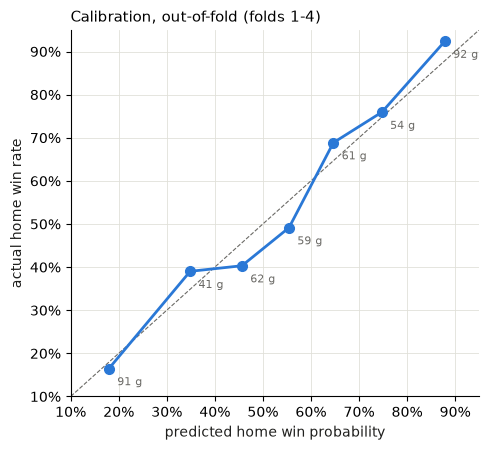

460 games predicted out-of-fold; log loss 0.5243


,games,predicted,actual
bin,,,
"(0.0, 0.3]",91,18.0%,16.5%
"(0.3, 0.4]",41,34.9%,39.0%
"(0.4, 0.5]",62,45.7%,40.3%
"(0.5, 0.6]",59,55.4%,49.2%
"(0.6, 0.7]",61,64.7%,68.9%
"(0.7, 0.8]",54,74.8%,75.9%
"(0.8, 1.0]",92,87.9%,92.4%


In [10]:
oof = np.full(len(data), np.nan)
for trn, tst in splits:
    oof[tst] = predict(FINAL, trn, tst, C=C_FINAL)
mask = ~np.isnan(oof)
cal = pd.DataFrame({"p": oof[mask], "win": y[mask]})
cal["bin"] = pd.cut(cal["p"], [0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1])
cal_t = cal.groupby("bin", observed=True).agg(games=("win", "size"), predicted=("p", "mean"), actual=("win", "mean"))

BLUE, MUTED, GRID, INK = "#2a78d6", "#6b6a66", "#e1e0d9", "#1f1f1d"
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls="--")
ax.plot(cal_t["predicted"], cal_t["actual"], "-o", color=BLUE, lw=2, ms=7)
for _, r in cal_t.iterrows():
    ax.annotate(f"{int(r['games'])} g", (r["predicted"], r["actual"]), textcoords="offset points",
                xytext=(6, -12), fontsize=8, color=MUTED)
ax.set_xlim(0.1, 0.95); ax.set_ylim(0.1, 0.95)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("predicted home win probability", color=INK)
ax.set_ylabel("actual home win rate", color=INK)
ax.set_title("Calibration, out-of-fold (folds 1-4)", loc="left", fontsize=11)
ax.grid(color=GRID, lw=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
print(f"{int(mask.sum())} games predicted out-of-fold; log loss {log_loss(y[mask], oof[mask]):.4f}")
cal_t.style.format({"predicted": "{:.1%}", "actual": "{:.1%}"})

## Conclusions

**1. The final feature set: three features plus the home ice switch.**

| Feature | Why it's in | Weight (odds × per SD) |
|---|---|---|
| Shots for per game (season) | The strongest single predictor (step 5) | 2.92 |
| Schedule-adjusted goal differential | Adds on top of shots: +0.0017, better in 2 of 3 folds | 2.14 |
| PDO (shooting % + save %, season) | Adds on top of both: +0.0028, better in 2 of 3 folds | **0.72** (negative) |
| Home ice switch | An evenly matched home team wins 52.9%; 50/50 at neutral sites by rule | — |

**2. PDO enters with a negative weight, and that's a correction, not a mistake.** On its own,
a higher PDO goes with winning (step 5). But once goal differential is in the model, a high
PDO says that goal differential was inflated by hot shooting or goaltending, which repeats
only partly (step 4: r = 0.42). So the model trusts that team's goal differential a little
less and leans on its shots. It's the luck-correction idea from step 4, learned from the data.

**3. Everything else adds nothing on top:** 3rd-period goal diff, special teams, % scoring
first, PP%, shooting %, PK%, save %, PIM, PP chances, streak, strength of schedule and recent
form. PIM came closest (+0.0005), below the minimum.

**4. C = 1.** C = 10 was better by 0.0009, within its standard error (0.0011).

**5. Fold 4 (the last 115 games, including the tournaments):**

| | Log loss | Brier | AUC | Accuracy |
|---|---|---|---|---|
| Always the home win rate | 0.683 | 0.245 | 0.500 | 60.0% |
| Win % only | 0.567 | 0.192 | 0.762 | 70.4% |
| **This model** | **0.541** | **0.184** | **0.781** | **73.9%** |

**6. Calibration is good** (out-of-fold, 460 games): within a few points in every group. The
model is a little too eager in the 50–60% range (predicted 55%, won 49%) and a little too
cautious at the top (predicted 88%, won 92%).

**7. Next:** step 9 fits these features on all of 2025-26, freezes them as
`win_model_women_v1`, and tests once on 2026-27.
